Dataset loaded successfully!
   Feature_1  Feature_2  Target
0  -0.111667   0.520224       1
1   1.142650  -0.342577       1
2   0.795558  -0.011442       1
3   0.111827  -0.551932       1
4  -0.816466   0.543996       0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Feature_1  1000 non-null   float64
 1   Feature_2  1000 non-null   float64
 2   Target     1000 non-null   int64  
dtypes: float64(2), int64(1)
memory usage: 23.6 KB
None
Columns: ['Feature_1', 'Feature_2', 'Target']
Missing values:
 Feature_1    0
Feature_2    0
Target       0
dtype: int64
Feature shape: (1000, 2)
Target shape: (1000,)
Target classes: [0 1]
Class distribution:
 1    500
0    500
Name: count, dtype: int64


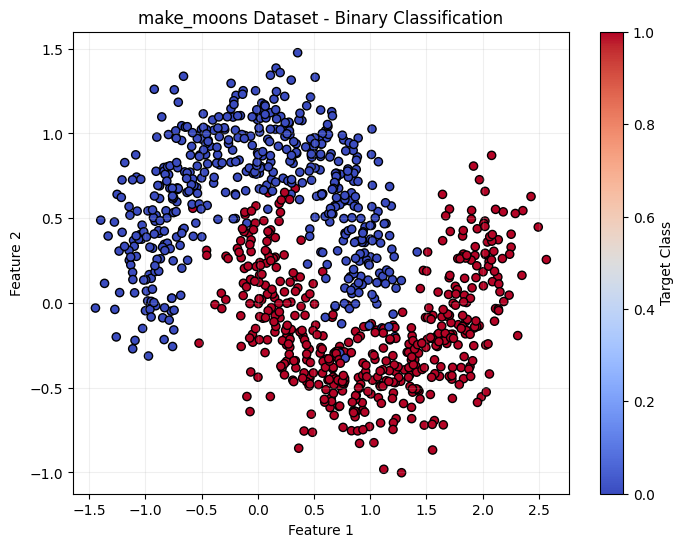

Training samples: 800
Testing samples: 200


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            48 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 337 (1.32 KB)

 Trainable params: 337 (1.32 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.7578 - loss: 0.5744 - val_accuracy: 0.8875 - val_loss: 0.3213
Epoch 2/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8469 - loss: 0.3484 - val_accuracy: 0.9000 - val_loss: 0.2308
Epoch 3/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8562 - loss: 0.3203 - val_accuracy: 0.9000 - val_loss: 0.2189
Epoch 4/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8609 - loss: 0.3016 - val_accuracy: 0.9062 - val_loss: 0.2086
Epoch 5/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8687 - loss: 0.2829 - val_accuracy: 0.9125 - val_loss: 0.1920
Epoch 6/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8719 - loss: 0.2648 - val_accuracy: 0.9187 - val_loss: 0.1781
Epoch 7/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8797 - loss: 0.2449 - val_accuracy: 0.9250 - val_loss: 0.1606
Epoch 8/200
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8953 - loss: 0.2157 - val_accuracy: 0.93

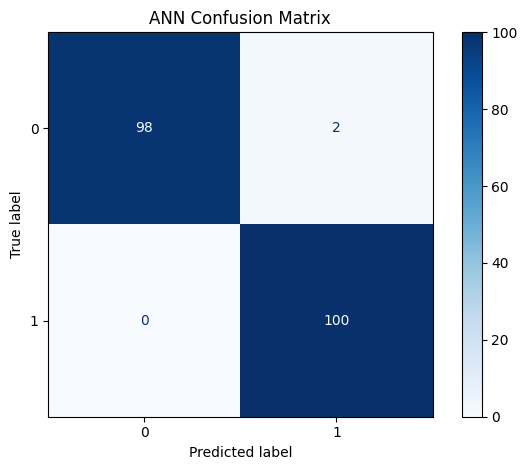

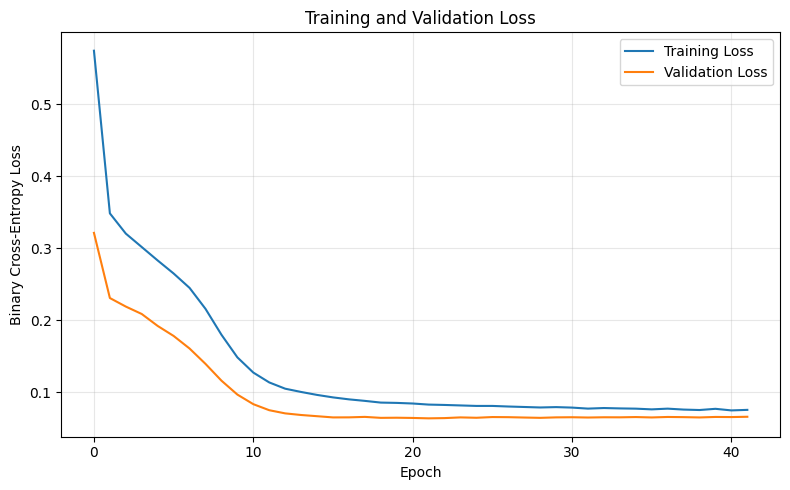

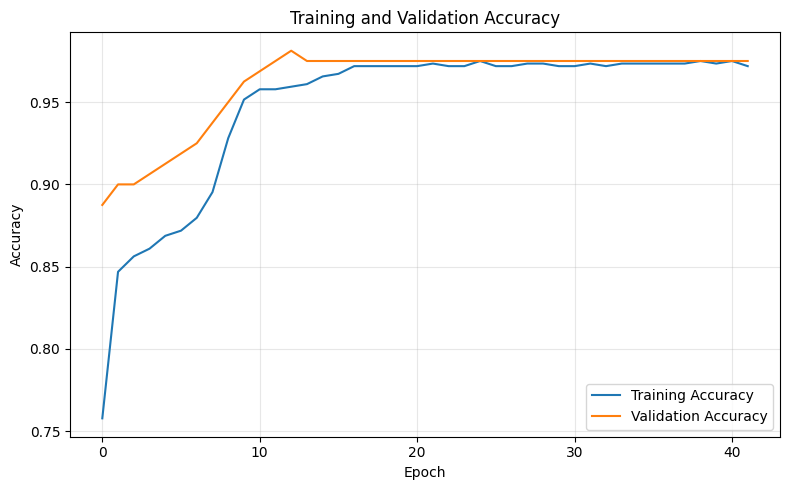

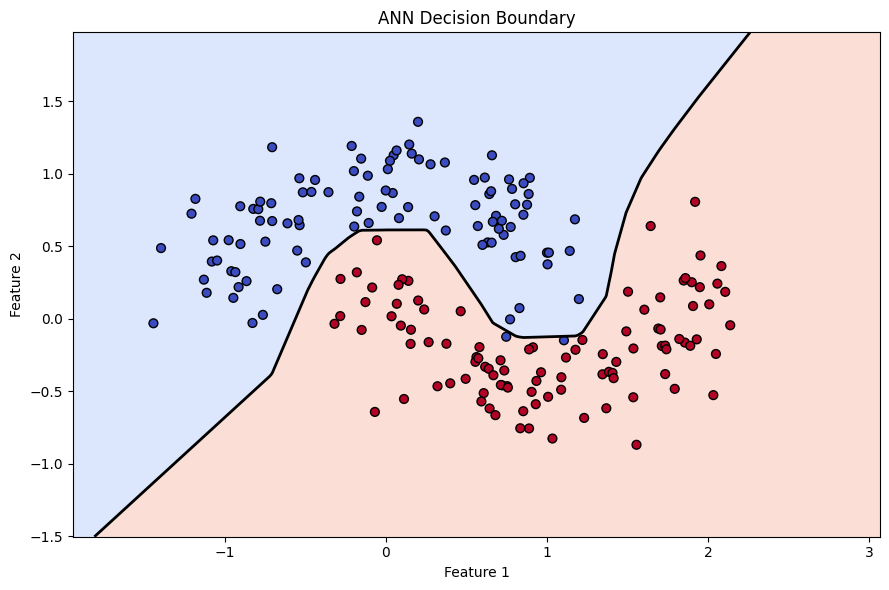

['/content/make_moons_scaler.pkl']

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

file_path = "/content/make_moons_binary_classification.csv"

if not os.path.exists(file_path):
    raise FileNotFoundError(
        f"CSV not found: {file_path}. Check the uploaded file path."
    )

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print(df.head())
print(df.info())
print("Columns:", df.columns.tolist())
print("Missing values:\n", df.isnull().sum())

required_columns = ["Feature_1", "Feature_2", "Target"]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}. "
        f"Available columns: {df.columns.tolist()}"
    )

df = df[required_columns].dropna().copy()

X = df[["Feature_1", "Feature_2"]].to_numpy(dtype=np.float32)
y = df["Target"].to_numpy()

if len(np.unique(y)) != 2:
    raise ValueError(
        f"Expected two target classes, found: {np.unique(y)}"
    )

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Target classes:", np.unique(y))
print("Class distribution:\n", pd.Series(y).value_counts())

plt.figure(figsize=(8, 6))
plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap="coolwarm",
    edgecolors="black",
    s=35
)
plt.title("make_moons Dataset - Binary Classification")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.colorbar(label="Target Class")
plt.grid(alpha=0.2)
plt.show()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

tf.keras.utils.set_random_seed(42)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(2,)),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_split=0.20,
    epochs=200,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

probabilities = model.predict(X_test, verbose=0).ravel()
y_pred = (probabilities >= 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)

print("\nTest Accuracy:", round(accuracy, 4))
print(f"Test Accuracy (%): {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    digits=4,
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:\n", cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues", values_format="d")
plt.title("ANN Confusion Matrix")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

x_min = X[:, 0].min() - 0.5
x_max = X[:, 0].max() + 0.5
y_min = X[:, 1].min() - 0.5
y_max = X[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]
grid_scaled = scaler.transform(grid)
zz = model.predict(grid_scaled, verbose=0).reshape(xx.shape)

plt.figure(figsize=(9, 6))
plt.contourf(
    xx,
    yy,
    zz,
    levels=[0, 0.5, 1],
    alpha=0.30,
    cmap="coolwarm"
)
plt.contour(
    xx,
    yy,
    zz,
    levels=[0.5],
    colors="black",
    linewidths=2
)

X_test_original = scaler.inverse_transform(X_test)

plt.scatter(
    X_test_original[:, 0],
    X_test_original[:, 1],
    c=y_test,
    cmap="coolwarm",
    edgecolors="black",
    s=40
)

plt.title("ANN Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.tight_layout()
plt.show()

model.save("/content/make_moons_ann.keras")
joblib.dump(scaler, "/content/make_moons_scaler.pkl")